Libraries imported successfully!
Dataset loaded successfully!
Dataset Shape: (1000, 8)

First 5 Records:
   gender race/ethnicity parental level of education         lunch  \
0  female        group D          associate's degree  free/reduced   
1    male        group C                 high school  free/reduced   
2    male        group E                 high school      standard   
3  female        group B                 high school      standard   
4    male        group B           bachelor's degree      standard   

  test preparation course  math score  reading score  writing score  
0               completed          51             68             69  
1                    none          62             65             56  
2                    none          98             93             88  
3               completed          65             63             73  
4                    none          74             74             67  

Dataset Information:
<class 'pandas.DataFrame'>
Range

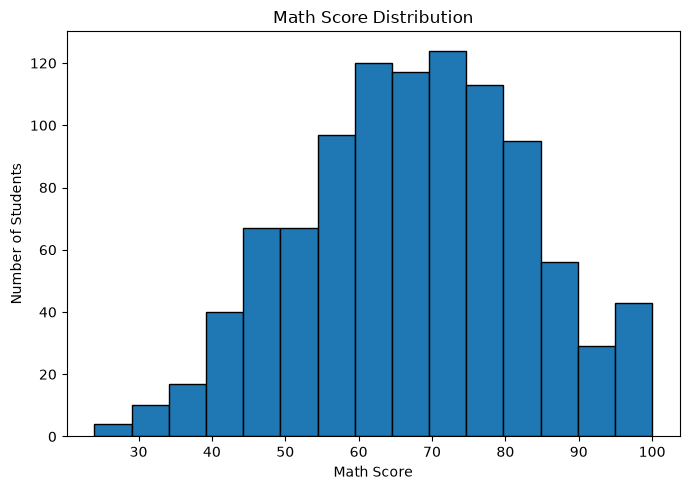

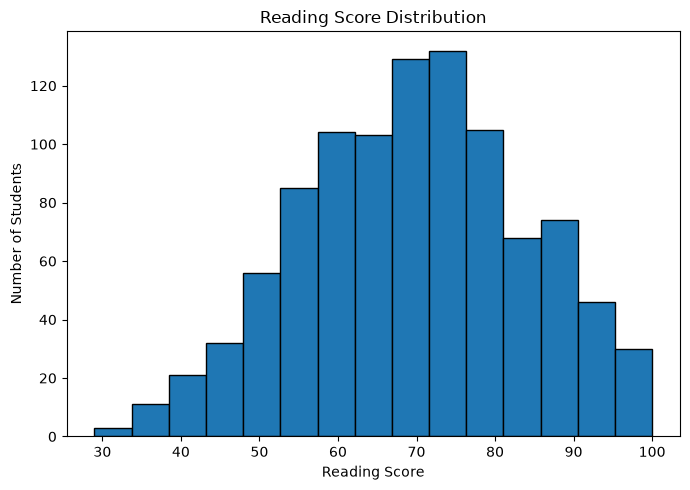

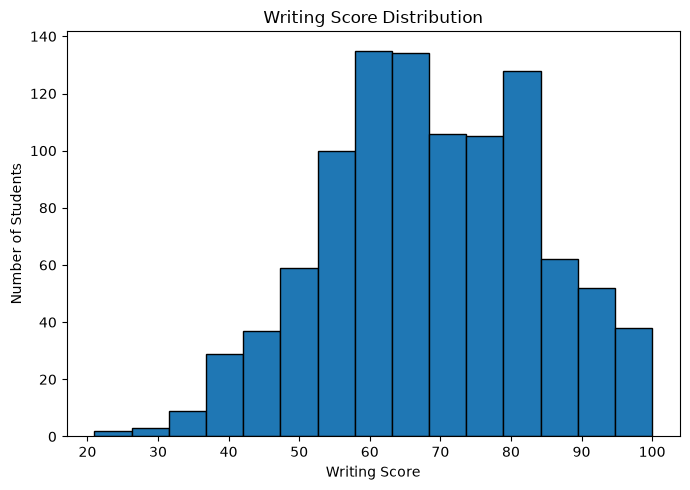

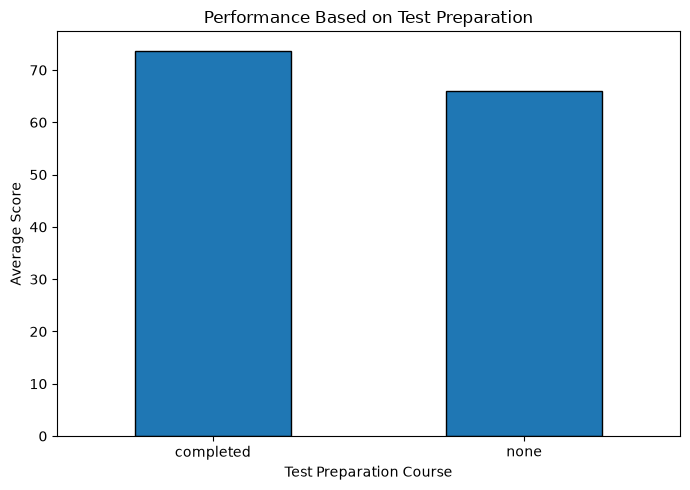


Features Selected:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']

Target Selected: average_score

Training Records: 799
Testing Records: 200

Model trained successfully!

Prediction Results:
   Actual Score  Predicted Score
0     77.333333        68.838339
1     61.000000        73.940495
2     63.666667        74.625154
3     94.666667        78.021687
4     63.666667        71.262532
5     57.666667        70.963274
6     67.000000        67.324543
7     60.000000        62.184171
8     54.333333        58.940070
9     55.000000        53.955424

========== MODEL EVALUATION ==========
Mean Absolute Error (MAE): 8.65
Root Mean Squared Error (RMSE): 10.68
R2 Score: 0.212


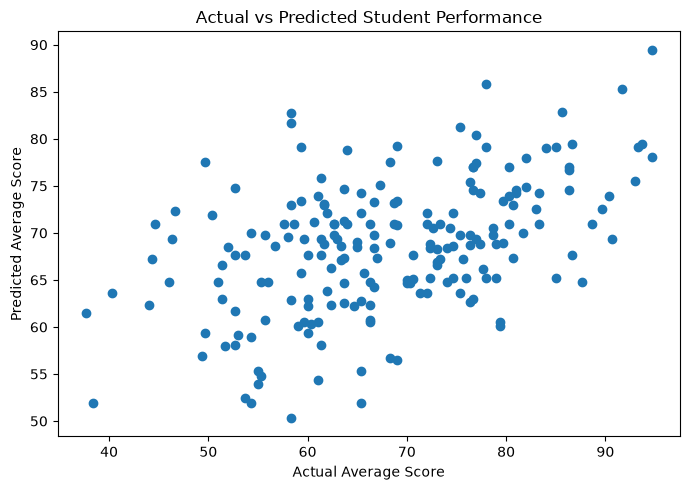


========== NEW STUDENT PREDICTION ==========
Predicted Average Score: 81.24

Prediction results saved!
Trained model saved!

       PROJECT COMPLETED SUCCESSFULLY!

1. Dataset loaded successfully.
2. Data cleaning performed.
3. Missing values handled.
4. Exploratory Data Analysis completed.
5. Visualizations generated.
6. Features and target selected.
7. Training and testing completed.
8. Linear Regression model trained.
9. Student performance predicted.
10. Model evaluation completed.
11. Output files saved successfully.

Project: Student Performance Prediction
Algorithm: Linear Regression




In [9]:

# ============================================================
# TASK 40: STUDENT PERFORMANCE PREDICTION
# VEDA TECHNOLOGY INTERNSHIP
# ============================================================


# 1. IMPORT LIBRARIES

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")


# 2. CREATE OUTPUT FOLDER

os.makedirs("visualizations", exist_ok=True)


# 3. LOAD DATASET

possible_files = [
    "student_performance.csv",
    "Student_Performance.csv"
]

dataset_file = next(
    (file for file in possible_files if os.path.exists(file)),
    None
)

if dataset_file is None:
    raise FileNotFoundError(
        "Dataset not found! Place Student_Performance.csv "
        "in the same folder as this notebook."
    )

df = pd.read_csv(dataset_file)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)


# 4. UNDERSTAND THE DATASET

print("\nFirst 5 Records:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe(include="all"))


# 5. CLEAN COLUMN NAMES

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
)

required_columns = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
    "math score",
    "reading score",
    "writing score"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

df = df[required_columns].copy()


# 6. REMOVE DUPLICATE RECORDS

print("\nDuplicate Records:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("Duplicates removed.")


# 7. HANDLE MISSING VALUES

score_columns = [
    "math score",
    "reading score",
    "writing score"
]

categorical_columns = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

# Convert scores into numeric values
for col in score_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Replace invalid scores with missing values
for col in score_columns:
    df.loc[
        (df[col] < 0) | (df[col] > 100),
        col
    ] = np.nan

# Fill missing score values with median
for col in score_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in categorical_columns:
    mode_value = df[col].mode()

    fill_value = (
        mode_value.iloc[0]
        if not mode_value.empty
        else "Unknown"
    )

    df[col] = df[col].fillna(fill_value).astype(str)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


# 8. CREATE AVERAGE SCORE

df["average_score"] = df[score_columns].mean(axis=1)

print("\nAverage Score Created Successfully!")


# 9. SAVE CLEANED DATASET

df.to_csv("cleaned_student_performance.csv", index=False)

print("Cleaned dataset saved!")


# 10. EXPLORATORY DATA ANALYSIS

print("\nAverage Student Performance:")
print(df["average_score"].describe())

print("\nAverage Score by Gender:")
print(df.groupby("gender")["average_score"].mean())

print("\nAverage Score by Test Preparation:")
print(
    df.groupby("test preparation course")[
        "average_score"
    ].mean()
)


# 11. MATH SCORE DISTRIBUTION

plt.figure(figsize=(7, 5))

plt.hist(df["math score"], bins=15, edgecolor="black")

plt.xlabel("Math Score")
plt.ylabel("Number of Students")
plt.title("Math Score Distribution")

plt.tight_layout()
plt.savefig("visualizations/math_score_distribution.png")
plt.show()


# 12. READING SCORE DISTRIBUTION

plt.figure(figsize=(7, 5))

plt.hist(df["reading score"], bins=15, edgecolor="black")

plt.xlabel("Reading Score")
plt.ylabel("Number of Students")
plt.title("Reading Score Distribution")

plt.tight_layout()
plt.savefig("visualizations/reading_score_distribution.png")
plt.show()


# 13. WRITING SCORE DISTRIBUTION

plt.figure(figsize=(7, 5))

plt.hist(df["writing score"], bins=15, edgecolor="black")

plt.xlabel("Writing Score")
plt.ylabel("Number of Students")
plt.title("Writing Score Distribution")

plt.tight_layout()
plt.savefig("visualizations/writing_score_distribution.png")
plt.show()


# 14. TEST PREPARATION ANALYSIS

preparation_scores = df.groupby(
    "test preparation course"
)["average_score"].mean()

plt.figure(figsize=(7, 5))

preparation_scores.plot(kind="bar", edgecolor="black")

plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")
plt.title("Performance Based on Test Preparation")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("visualizations/test_preparation_scores.png")
plt.show()


# 15. SELECT FEATURES AND TARGET

features = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

X = df[features]
y = df["average_score"]

print("\nFeatures Selected:")
print(features)

print("\nTarget Selected: average_score")


# 16. SPLIT TRAINING AND TESTING DATA

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])


# 17. PREPROCESSING AND MODEL SELECTION

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            features
        )
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)


# 18. TRAIN MODEL AND MAKE PREDICTIONS

model.fit(X_train, y_train)

print("\nModel trained successfully!")

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": y_pred
})

print("\nPrediction Results:")
print(results.head(10))


# 19. MODEL EVALUATION

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("\n========== MODEL EVALUATION ==========")

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 3))


# 20. ACTUAL VS PREDICTED GRAPH

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Average Score")
plt.ylabel("Predicted Average Score")
plt.title("Actual vs Predicted Student Performance")

plt.tight_layout()

plt.savefig("visualizations/actual_vs_predicted.png")
plt.show()


# 21. EXAMPLE STUDENT PREDICTION

new_student = pd.DataFrame([{
    "gender": "female",
    "race/ethnicity": "group B",
    "parental level of education": "bachelor's degree",
    "lunch": "standard",
    "test preparation course": "completed"
}])

prediction = model.predict(new_student)[0]

print("\n========== NEW STUDENT PREDICTION ==========")

print(
    "Predicted Average Score:",
    round(prediction, 2)
)


# 22. SAVE OUTPUT FILES

results.to_csv(
    "student_prediction_results.csv",
    index=False
)

joblib.dump(
    model,
    "student_performance_model.pkl"
)

print("\nPrediction results saved!")
print("Trained model saved!")


# 23. PROJECT CONCLUSION

print("""
================================================
       PROJECT COMPLETED SUCCESSFULLY!
================================================

1. Dataset loaded successfully.
2. Data cleaning performed.
3. Missing values handled.
4. Exploratory Data Analysis completed.
5. Visualizations generated.
6. Features and target selected.
7. Training and testing completed.
8. Linear Regression model trained.
9. Student performance predicted.
10. Model evaluation completed.
11. Output files saved successfully.

Project: Student Performance Prediction
Algorithm: Linear Regression

================================================
""")
